# Segundo Avance — Proyecto de aula · Minería de Datos
## Modelo de clasificación para la predicción temprana de diabetes tipo 2 a partir de indicadores clínicos

**Autor:** Juan Ortega
**Curso:** Minería de Datos — Universidad de la Costa (CUC) · **Departamento:** Ciencias de la Computación y Electrónica
**Tipo de proyecto:** Clasificación (binaria) — investigación aplicada
**Pregunta de investigación:** ¿Es posible clasificar, a partir de indicadores clínicos básicos, si una paciente del conjunto Pima presenta diabetes, y qué tipo de error resulta más relevante para este problema?
**Dataset:** Pima Indians Diabetes Database (NIDDK; Smith et al., 1988). Descarga: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database. 768 registros, 8 predictoras numéricas.
**Variable objetivo:** `Outcome` (1 = diabética, 0 = no diabética).
**Período:** Corte 2 — EDA, preparación para modelado, entrenamiento y evaluación de modelos.

## 1. Descripción del conjunto de datos

El conjunto de datos utilizado es **Pima Indians Diabetes Dataset**, originalmente publicado por el
National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK). Contiene registros médicos
de **768 pacientes mujeres** de al menos 21 años, de ascendencia Pima (Arizona, EE.UU.), con el
objetivo de predecir si una paciente desarrollará diabetes tipo 2 (variable `Outcome`) a partir de
mediciones clínicas y demográficas.

Este dataset fue seleccionado porque:
- Contiene exactamente las variables clínicas mencionadas en el objetivo del proyecto (glucosa,
  presión arterial, IMC, antecedentes de embarazos).
- Es un problema de **clasificación binaria** (0 = no diabética, 1 = diabética), adecuado para
  comparar distintos algoritmos de clasificación en los siguientes períodos.
- Es un dataset ampliamente documentado en la literatura, lo que facilita comparar resultados
  propios contra trabajos previos.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("diabetes.csv")
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Descripción de las variables

| Variable | Tipo | Descripción |
|---|---|---|
| `Pregnancies` | Numérica (entera) | Número de embarazos previos |
| `Glucose` | Numérica (entera) | Concentración de glucosa en plasma (prueba de tolerancia oral, 2h) |
| `BloodPressure` | Numérica (entera) | Presión arterial diastólica (mm Hg) |
| `SkinThickness` | Numérica (entera) | Grosor del pliegue cutáneo del tríceps (mm) |
| `Insulin` | Numérica (entera) | Insulina sérica a las 2 horas (mu U/ml) |
| `BMI` | Numérica (decimal) | Índice de masa corporal (peso en kg / (altura en m)^2) |
| `DiabetesPedigreeFunction` | Numérica (decimal) | Función que estima la probabilidad de diabetes según antecedentes familiares |
| `Age` | Numérica (entera) | Edad de la paciente (años) |
| `Outcome` | Categórica (binaria) | Variable objetivo: 1 = diabética, 0 = no diabética |

Todas las variables predictoras son numéricas, lo cual simplifica la fase de preparación de datos
(no se requiere codificación de variables categóricas en este dataset).


In [2]:
# Dimensiones y tipos de datos
print("Dimensiones del dataset:", df.shape)
print()
print("Tipos de datos:")
print(df.dtypes)


Dimensiones del dataset: (768, 9)

Tipos de datos:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [3]:
# Estadísticas descriptivas generales
df.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 3. Diagnóstico inicial de calidad de datos

Un primer chequeo con `isnull()` no muestra valores faltantes explícitos. Sin embargo, este dataset
es un caso conocido en el que los valores faltantes fueron codificados como **cero (0)** en variables
donde un valor de cero es clínicamente imposible (por ejemplo, glucosa o presión arterial igual a 0).
Por eso se revisan por separado los ceros en las columnas donde no tienen sentido fisiológico.


In [4]:
# Valores nulos explícitos
print("Valores nulos por columna:")
print(df.isnull().sum())
print()

# Duplicados
print("Filas duplicadas:", df.duplicated().sum())


Valores nulos por columna:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Filas duplicadas: 0


In [5]:
# Ceros clínicamente imposibles (posibles valores faltantes disfrazados)
cols_sin_ceros_validos = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

resumen_ceros = pd.DataFrame({
    "columna": cols_sin_ceros_validos,
    "num_ceros": [(df[c] == 0).sum() for c in cols_sin_ceros_validos],
    "porcentaje": [round((df[c] == 0).mean() * 100, 1) for c in cols_sin_ceros_validos]
})
resumen_ceros


,columna,num_ceros,porcentaje
0,Glucose,5,0.7
1,BloodPressure,35,4.6
2,SkinThickness,227,29.6
3,Insulin,374,48.7
4,BMI,11,1.4


**Hallazgos del diagnóstico inicial:**

- No hay valores nulos explícitos (`NaN`) ni filas duplicadas en el dataset.
- Sin embargo, se identificaron **valores de cero clínicamente imposibles** que funcionan como
  valores faltantes ocultos:
  - `Insulin`: 374 registros en cero (~48.7% del dataset) — el problema más severo.
  - `SkinThickness`: 227 registros en cero (~29.6%).
  - `BloodPressure`: 35 registros en cero (~4.6%).
  - `BMI`: 11 registros en cero (~1.4%).
  - `Glucose`: 5 registros en cero (~0.7%).
- La variable objetivo `Outcome` está moderadamente desbalanceada: 500 pacientes sin diabetes (65.1%)
  frente a 268 con diabetes (34.9%). Esto deberá tenerse en cuenta al entrenar y evaluar los modelos
  en los siguientes períodos (por ejemplo, evitar depender solo de la exactitud como métrica).


## 4. Proceso de limpieza (fase inicial) — versión usada solo para EDA

En este primer período se realiza una limpieza preliminar: se reemplazan los ceros clínicamente
imposibles por `NaN` para tratarlos explícitamente como valores faltantes, y se imputan usando la
**mediana** de cada variable (más robusta que la media frente a valores atípicos). La estrategia de
imputación definitiva (mediana simple, imputación por grupo según `Outcome`, KNN imputer, etc.) se
terminará de evaluar y justificar en el siguiente período, junto con la fase de modelado.


> **Nota (corte 2):** esta imputación con la mediana de *todo* el dataset se conserva únicamente para el análisis exploratorio. Para el modelado se usa una imputación dentro de un `Pipeline` ajustada solo con los datos de entrenamiento (ver sección 10), para evitar fuga de información.

In [6]:
df_limpio = df.copy()

# Paso 1: reemplazar ceros clínicamente imposibles por NaN
for c in cols_sin_ceros_validos:
    df_limpio[c] = df_limpio[c].replace(0, np.nan)

print("Valores faltantes tras marcar los ceros como NaN:")
print(df_limpio.isnull().sum())


Valores faltantes tras marcar los ceros como NaN:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [7]:
# Paso 2: imputación preliminar con la mediana de cada columna
for c in cols_sin_ceros_validos:
    mediana = df_limpio[c].median()
    df_limpio[c] = df_limpio[c].fillna(mediana)

print("Valores faltantes después de la imputación:")
print(df_limpio.isnull().sum())
print()
df_limpio.describe()


Valores faltantes después de la imputación:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,29.108073,140.671875,32.455208,0.471876,33.240885,0.348958
std,3.369578,30.438286,12.096642,8.791221,86.383060,6.875177,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 5. Visualizaciones exploratorias

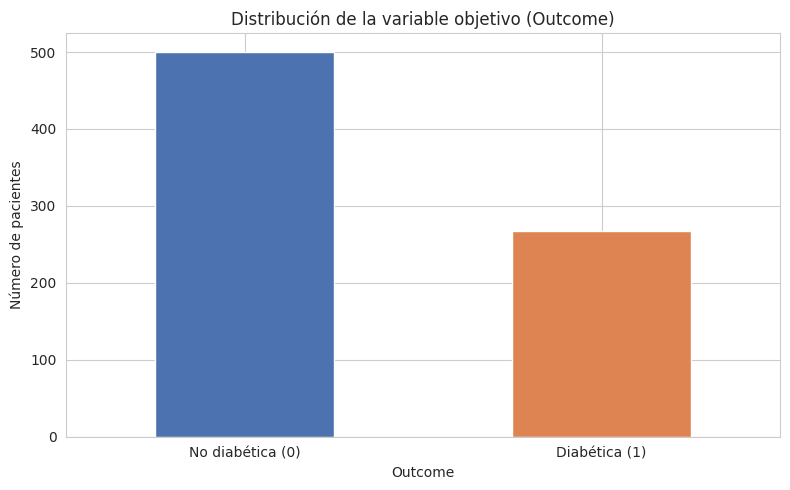

In [8]:
# Distribución de la variable objetivo
fig, ax = plt.subplots()
df["Outcome"].value_counts().sort_index().plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_xticklabels(["No diabética (0)", "Diabética (1)"], rotation=0)
ax.set_ylabel("Número de pacientes")
ax.set_title("Distribución de la variable objetivo (Outcome)")
plt.tight_layout()
plt.show()


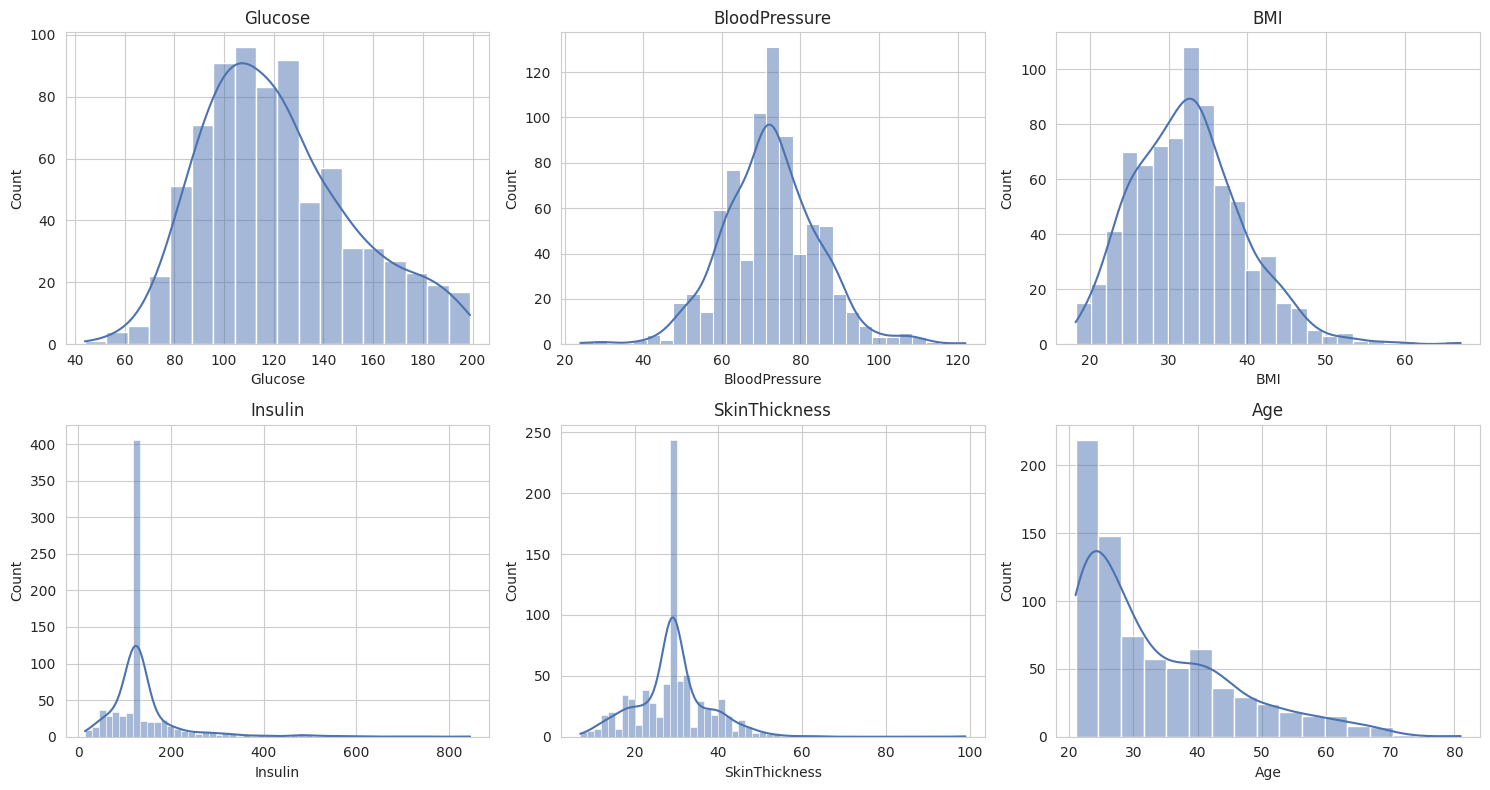

In [9]:
# Distribución de las variables numéricas principales (después de la limpieza)
variables = ["Glucose", "BloodPressure", "BMI", "Insulin", "SkinThickness", "Age"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), variables):
    sns.histplot(df_limpio[col], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col)
plt.tight_layout()
plt.show()


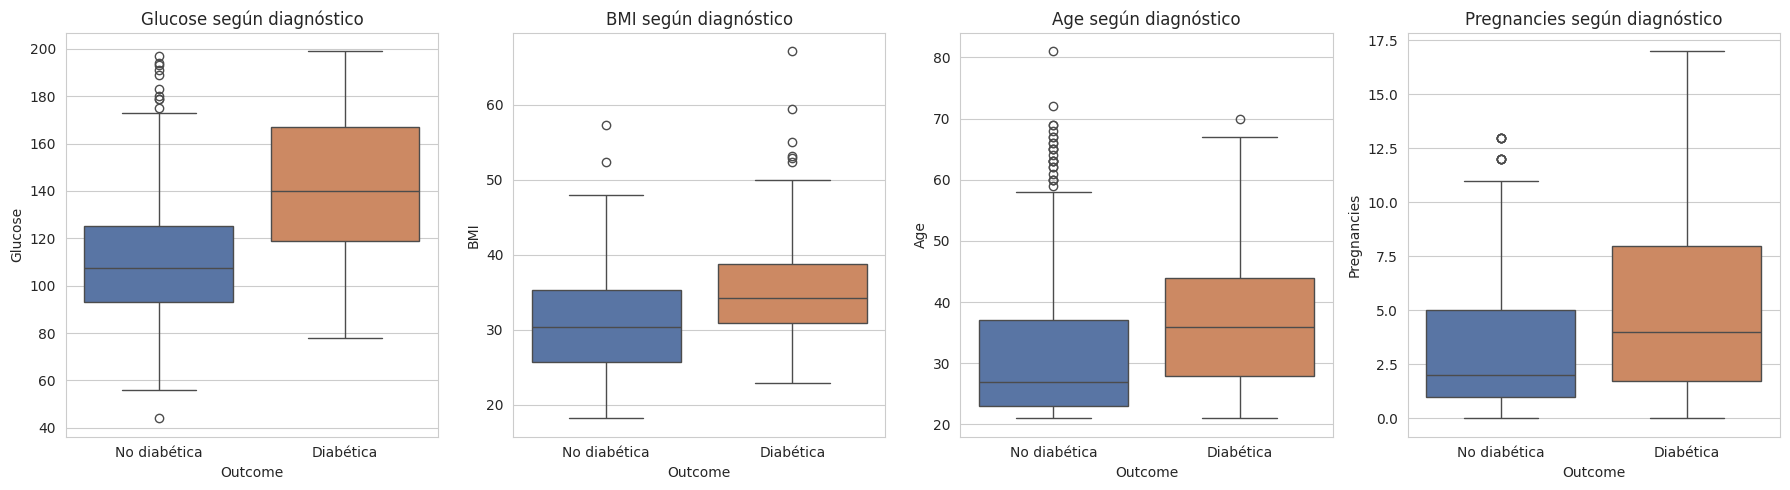

In [10]:
# Comparación de variables clave según diagnóstico (Outcome)
variables_clave = ["Glucose", "BMI", "Age", "Pregnancies"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, variables_clave):
    sns.boxplot(data=df_limpio, x="Outcome", y=col, hue="Outcome", legend=False,
                ax=ax, palette=["#4C72B0", "#DD8452"])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No diabética", "Diabética"])
    ax.set_title(f"{col} según diagnóstico")
plt.tight_layout()
plt.show()

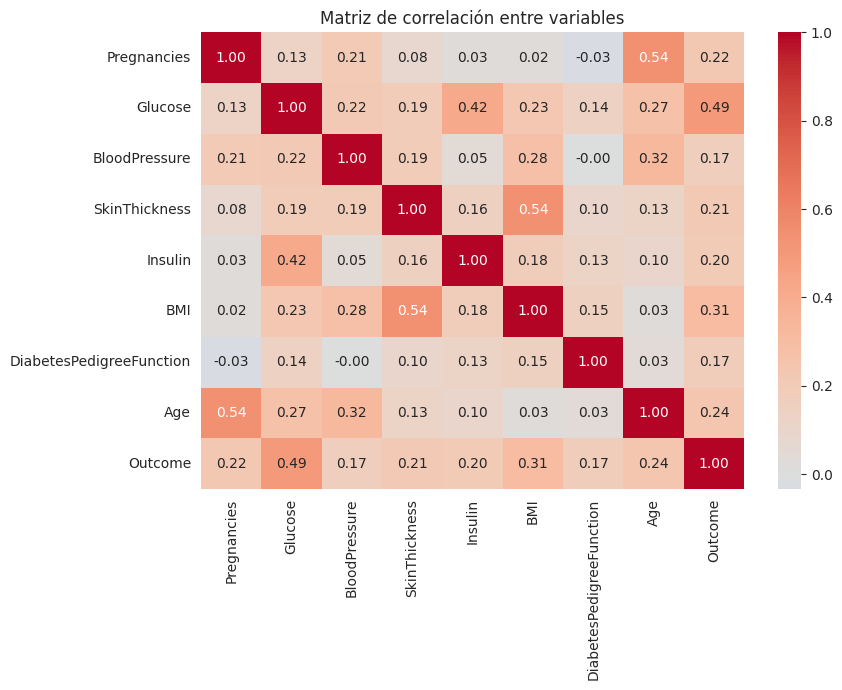

In [11]:
# Matriz de correlación entre variables
plt.figure(figsize=(9, 7))
corr = df_limpio.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación entre variables")
plt.tight_layout()
plt.show()


**Lectura preliminar de las visualizaciones:**

- Las pacientes diagnosticadas con diabetes (`Outcome = 1`) muestran de forma visible niveles de
  **glucosa** más altos que las no diagnosticadas, lo cual es consistente con el criterio clínico
  usado para definir la enfermedad.
- El **IMC** y la **edad** también muestran diferencias entre ambos grupos, aunque con más
  solapamiento que la glucosa.
- La matriz de correlación muestra que `Glucose` es la variable con mayor correlación positiva con
  `Outcome`, seguida de `BMI`, `Age` y `Pregnancies`. Ninguna variable predictora muestra
  correlaciones extremadamente altas entre sí, por lo que no se anticipan problemas graves de
  multicolinealidad para el modelado.


## 6. Registro de uso de IA (primer avance)

- **Propósito del uso de la IA:** apoyo en la redacción de la introducción y el estado del arte del
  documento PDF, búsqueda y verificación de referencias académicas del Departamento de Ciencias de
  la Computación y Electrónica de la CUC, y estructuración inicial de este cuaderno (diagnóstico de
  calidad de datos, limpieza preliminar y visualizaciones exploratorias).
- **¿Qué respuesta fue útil?** La identificación automática de los ceros clínicamente imposibles
  como valores faltantes ocultos, y la sugerencia de usar la mediana (en lugar de la media) para la
  imputación preliminar dado el número de valores faltantes en `Insulin` y `SkinThickness`.
- **Lo que había que corregir, validar o ajustar:** se verificó manualmente que las cinco
  referencias del estado del arte correspondieran a publicaciones reales de autores del
  departamento (no inventadas por el modelo), confirmando autores, año y DOI contra fuentes
  primarias antes de incluirlas en el documento final.
- **Decisiones tomadas por el grupo y no por la herramienta de IA:** la elección del dataset
  (Pima Indians Diabetes) y la definición del problema como clasificación binaria fueron decisiones
  del equipo, tomadas antes de usar la IA. La estrategia definitiva de imputación de valores
  faltantes y la selección de algoritmos de clasificación para el siguiente período quedan
  pendientes de decisión del grupo, con apoyo de la IA como una segunda opinión, no como
  reemplazo del criterio propio.


## 7. Conclusión inicial (primer avance)

En esta primera revisión del conjunto de datos se confirmó que el dataset Pima Indians Diabetes es
adecuado para el objetivo del proyecto: contiene las variables clínicas necesarias (glucosa, presión
arterial, IMC, embarazos) y una variable objetivo binaria clara. El principal problema de calidad de
datos identificado fue la presencia de **ceros clínicamente imposibles** en cinco variables, que
actúan como valores faltantes ocultos, siendo especialmente severo en `Insulin` (48.7%) y
`SkinThickness` (29.6%). Como ajuste inicial, se marcaron estos ceros como valores nulos y se
imputaron de forma preliminar con la mediana de cada variable, únicamente con fines exploratorios.

Durante el segundo período académico se espera: (1) definir y justificar la estrategia de
imputación definitiva (comparando mediana simple, imputación por grupo según `Outcome` e
imputación por KNN), (2) tratar el desbalance moderado de la variable `Outcome`, y (3) entrenar y
comparar distintos algoritmos de clasificación (por ejemplo, regresión logística, árboles de
decisión y random forest) sobre el conjunto de datos limpio, evaluando su desempeño con métricas
adecuadas para un problema desbalanceado (precisión, recall, F1-score y AUC-ROC), en línea con el
enfoque metodológico revisado en el estado del arte.


---
# CORTE 2
## 8. Cambios frente al primer avance

| Cambio | Justificación |
|---|---|
| La imputación con mediana pasa a hacerse **dentro de un `Pipeline`, ajustada solo con entrenamiento**. | Calcular la mediana con todo el dataset filtra información del conjunto de prueba (*data leakage*). La versión global (`df_limpio`) queda solo para EDA. |
| Se imprimen los conteos de `Outcome` y las correlaciones con la variable objetivo. | En el primer avance estas cifras se afirmaban en texto sin mostrarlas. |
| Se corrigieron las advertencias de `seaborn`/`matplotlib` del boxplot. | Código más limpio y reproducible. |
| No se cambió el dataset, la pregunta ni la variable objetivo. | Continuidad con el primer avance. |


## 9. Análisis exploratorio de datos (EDA) orientado a la pregunta

### 9.1 Variable objetivo y desbalance

In [12]:
conteo = df["Outcome"].value_counts().sort_index()
prop = (df["Outcome"].value_counts(normalize=True).sort_index() * 100).round(1)
print(pd.DataFrame({"pacientes": conteo, "porcentaje": prop}).rename(index={0: "No diabética (0)", 1: "Diabética (1)"}))

                  pacientes  porcentaje
Outcome                                
No diabética (0)        500        65.1
Diabética (1)           268        34.9


**Interpretación:** hay un desbalance moderado (~65 % / 35 %). Un modelo que predijera siempre «no diabética» tendría ~65 % de accuracy sin detectar a ninguna paciente enferma, por eso el accuracy no será el único criterio de comparación.

### 9.2 ¿Los valores faltantes (ceros) se distribuyen igual en ambas clases?

In [13]:
falt = pd.DataFrame({
    c: (df[df["Outcome"] == k][c] == 0).mean() * 100
    for c in cols_sin_ceros_validos for k in [0]
}, index=["% ceros en No diabética"]).T
falt["% ceros en Diabética"] = [(df[df["Outcome"] == 1][c] == 0).mean() * 100 for c in cols_sin_ceros_validos]
print(falt.round(1))

               % ceros en No diabética  % ceros en Diabética
Glucose                            0.6                   0.7
BloodPressure                      3.8                   6.0
SkinThickness                     27.8                  32.8
Insulin                           47.2                  51.5
BMI                                1.8                   0.7


**Interpretación:** si el porcentaje de ceros difiere entre clases, la ausencia del dato podría estar asociada al diagnóstico (no es completamente aleatoria). Esto justifica evaluar en el futuro un indicador de «dato faltante» o imputación más sofisticada; en este corte se usa la mediana como línea base.

### 9.3 Valores atípicos

Pregnancies                   4
Glucose                       0
BloodPressure                14
SkinThickness                87
Insulin                     346
BMI                           8
DiabetesPedigreeFunction     29
Age                           9
Name: n_atípicos (regla IQR), dtype: int64


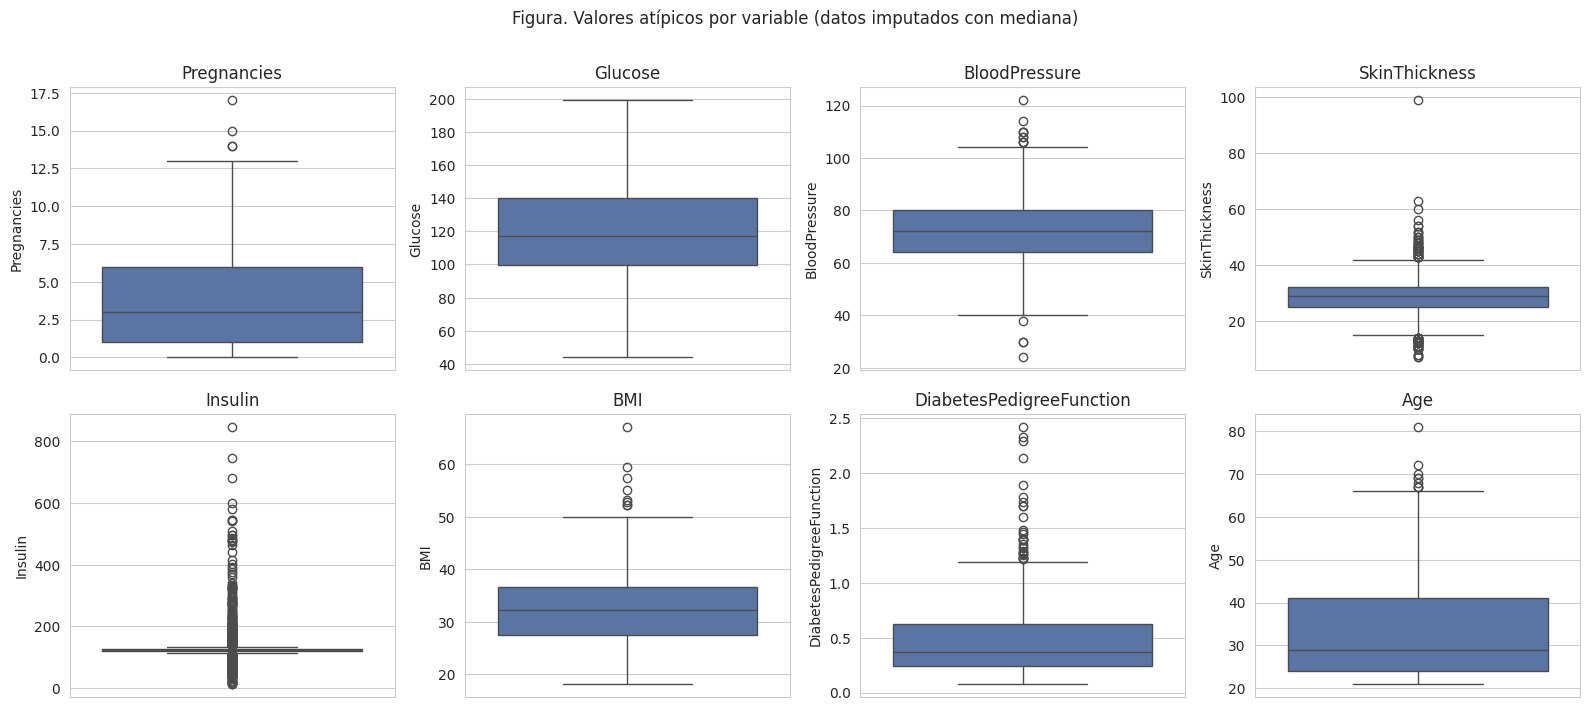

In [14]:
num_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
def n_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
print(pd.Series({c: n_outliers(df_limpio[c]) for c in num_cols}, name="n_atípicos (regla IQR)"))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df_limpio[col], ax=ax, color="#4C72B0")
    ax.set_title(col)
fig.suptitle("Figura. Valores atípicos por variable (datos imputados con mediana)", y=1.01)
plt.tight_layout()
plt.show()

**Decisión:** no se eliminan registros atípicos. Valores como `Insulin` alta o `Pregnancies` elevado son clínicamente posibles; eliminarlos reduciría la muestra (768 registros) y podría quitar justamente casos de riesgo. Los modelos de árbol son robustos a estos valores y en regresión logística se usa escalamiento. Parte de los «atípicos» de `Insulin` y `SkinThickness` se debe al pico artificial creado por la imputación con mediana.

### 9.4 Distribución por diagnóstico

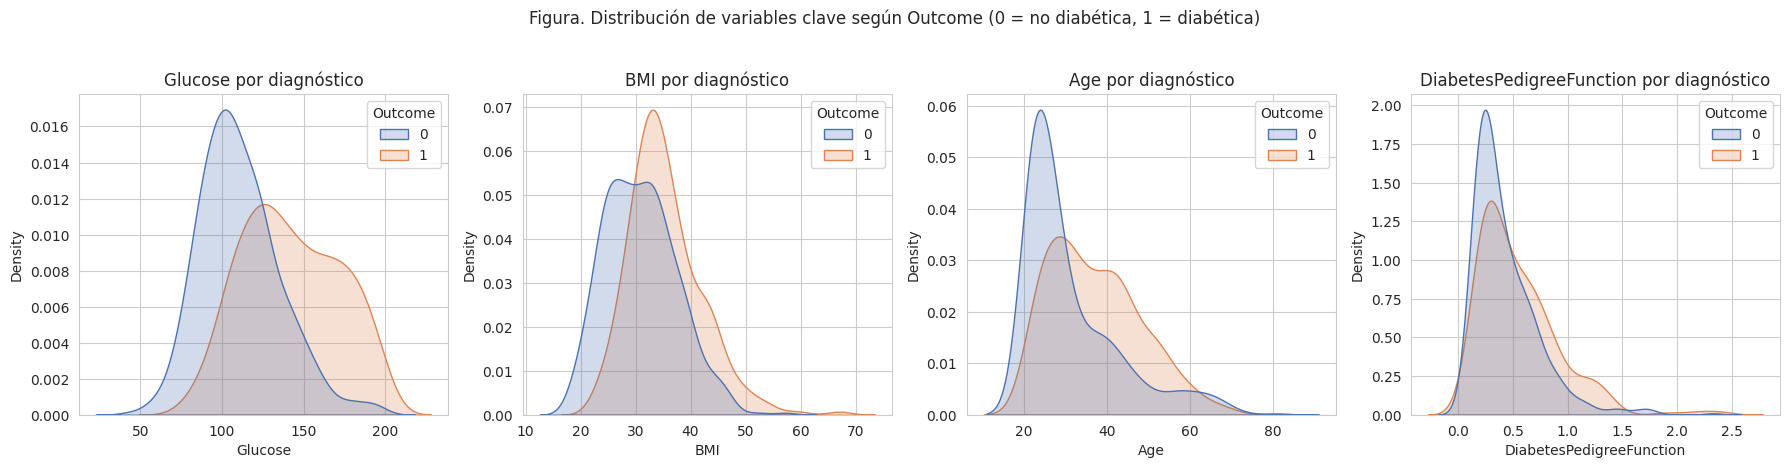

In [15]:
vars_kde = ["Glucose", "BMI", "Age", "DiabetesPedigreeFunction"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, vars_kde):
    sns.kdeplot(data=df_limpio, x=col, hue="Outcome", common_norm=False, fill=True, ax=ax,
                palette=["#4C72B0", "#DD8452"])
    ax.set_title(f"{col} por diagnóstico")
fig.suptitle("Figura. Distribución de variables clave según Outcome (0 = no diabética, 1 = diabética)", y=1.03)
plt.tight_layout()
plt.show()

**Interpretación:** la glucosa separa mejor a las dos clases (la curva de las diabéticas se desplaza a la derecha); IMC, edad y antecedente familiar muestran diferencias menores con solapamiento amplio. Son asociaciones, no relaciones causales.

### 9.5 Tasa de diabetes por grupos de edad e IMC

              n  % con diabetes
Grupo_edad                     
21-30       417            21.6
31-40       157            48.4
41-50       113            56.6
51+          81            46.9 

                 n  % con diabetes
Categoria_IMC                     
<25            112             6.2
25-30          180            24.4
>30            476            45.6 



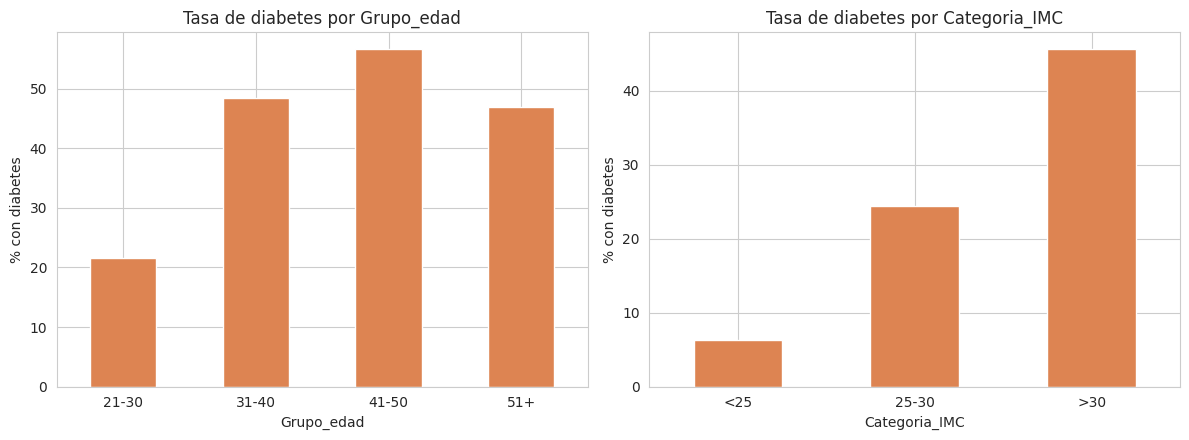

In [16]:
tmp = df_limpio.copy()
tmp["Grupo_edad"] = pd.cut(tmp["Age"], [20, 30, 40, 50, 90], labels=["21-30", "31-40", "41-50", "51+"])
tmp["Categoria_IMC"] = pd.cut(tmp["BMI"], [0, 25, 30, 100], labels=["<25", "25-30", ">30"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, ["Grupo_edad", "Categoria_IMC"]):
    tasa = tmp.groupby(col, observed=True)["Outcome"].mean() * 100
    tasa.plot(kind="bar", ax=ax, color="#DD8452", rot=0)
    ax.set_ylabel("% con diabetes"); ax.set_title(f"Tasa de diabetes por {col}")
    tam = tmp.groupby(col, observed=True).size()
    print(pd.DataFrame({"n": tam, "% con diabetes": tasa.round(1)}).to_string(), "\n")
plt.tight_layout()
plt.show()

**Interpretación:** la proporción de pacientes diabéticas aumenta con el IMC (6,2 % con IMC <25 frente a 45,6 % con IMC >30) y es mucho menor en el grupo de 21-30 años (21,6 %) que en los de 31-50 años (48,4 % y 56,6 %); en el grupo de 51+ baja ligeramente (46,9 %); es el grupo más pequeño (81 pacientes), por lo que su tasa es menos estable. Esto respalda el uso de ambas como predictoras, aunque son asociaciones y no implican causalidad.

### 9.6 Correlaciones con la variable objetivo

In [17]:
corr_obj = df_limpio.corr()["Outcome"].drop("Outcome").sort_values(ascending=False)
print(corr_obj.round(3))
print()
c = df_limpio.drop(columns="Outcome").corr()
pares = (c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack().sort_values(ascending=False))
print("Pares de predictoras más correlacionados:")
print(pares.head(4).round(3))

Glucose                     0.493
BMI                         0.312
Age                         0.238
Pregnancies                 0.222
SkinThickness               0.215
Insulin                     0.204
DiabetesPedigreeFunction    0.174
BloodPressure               0.166
Name: Outcome, dtype: float64

Pares de predictoras más correlacionados:
Pregnancies    Age        0.544
SkinThickness  BMI        0.543
Glucose        Insulin    0.419
BloodPressure  Age        0.325
dtype: float64


**Interpretación:** `Glucose` es la variable más asociada a `Outcome`. Entre predictoras no hay correlaciones extremas (la mayor es moderada), por lo que no se anticipa multicolinealidad grave, aunque `Age`–`Pregnancies` y `SkinThickness`–`BMI` están moderadamente relacionadas.

## 10. Preparación de datos para el modelado

Versión final usada para entrenar: el dataset original (768 registros, 8 predictoras + `Outcome`), con los ceros imposibles marcados como `NaN` en las 5 columnas indicadas. **No se eliminan registros ni variables.** No hay identificadores ni variables que filtren la respuesta, aunque se debe tener en cuenta que la glucosa a 2 h forma parte de los criterios clínicos de diagnóstico (ver limitaciones).

La imputación (mediana) y el escalamiento se aplican dentro de un `Pipeline`, de modo que se aprenden **solo con el conjunto de entrenamiento**.

In [18]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

SEED = 42
X = df.drop(columns="Outcome").copy()
y = df["Outcome"]
X[cols_sin_ceros_validos] = X[cols_sin_ceros_validos].replace(0, np.nan)   # marcar faltantes (no aprende nada de los datos)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("% diabéticas en entrenamiento:", round(y_train.mean() * 100, 1), "| en prueba:", round(y_test.mean() * 100, 1))

Entrenamiento: (614, 8) | Prueba: (154, 8)
% diabéticas en entrenamiento: 34.9 | en prueba: 35.1


Se usa una división 80/20 **estratificada** por `Outcome` para conservar la proporción de clases en ambos conjuntos, con semilla fija para reproducibilidad.

## 11. Selección y entrenamiento de modelos

| Modelo | Por qué se eligió |
|---|---|
| **Regresión logística** (con escalamiento) | Línea base interpretable para clasificación binaria; los coeficientes indican dirección e importancia relativa. |
| **Árbol de decisión** (`max_depth=4`) | Captura relaciones no lineales/interacciones y es fácil de interpretar. Se fija una profundidad máxima de 4 solo para evitar sobreajuste extremo; **no se realizó búsqueda de hiperparámetros**. |
| **Random forest** (200 árboles) | Modelo de conjunto adicional para contrastar contra los modelos simples. |

Los tres usan `class_weight="balanced"` para compensar el desbalance (~65/35).

In [19]:
def prep(scale):
    pasos = [("imputer", SimpleImputer(strategy="median"))]
    if scale: pasos.append(("scaler", StandardScaler()))
    return pasos

modelos = {
    "Regresión logística": Pipeline(prep(True) + [("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED))]),
    "Árbol de decisión":   Pipeline(prep(False) + [("clf", DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED))]),
    "Random forest":       Pipeline(prep(False) + [("clf", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED))]),
}
for nombre, m in modelos.items():
    m.fit(X_train, y_train)
print("Modelos entrenados:", list(modelos))

Modelos entrenados: ['Regresión logística', 'Árbol de decisión', 'Random forest']


## 12. Evaluación e interpretación

In [20]:
filas, preds, probas = [], {}, {}
for nombre, m in modelos.items():
    p = m.predict(X_test); pr = m.predict_proba(X_test)[:, 1]
    preds[nombre], probas[nombre] = p, pr
    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
        "AUC-ROC": roc_auc_score(y_test, pr),
        "F1 entrenamiento": f1_score(y_train, m.predict(X_train)),
    })
tabla = pd.DataFrame(filas).set_index("Modelo").round(3)
tabla

,Accuracy,Precision,Recall,F1,AUC-ROC,F1 entrenamiento
Modelo,,,,,,
Regresión logística,0.734,0.603,0.704,0.650,0.813,0.673
Árbol de decisión,0.708,0.556,0.833,0.667,0.767,0.734
Random forest,0.740,0.652,0.556,0.600,0.812,1.000


*Precision, Recall y F1 se calculan para la clase positiva (1 = diabética).* La columna «F1 entrenamiento» permite comparar entrenamiento vs. prueba para detectar sobreajuste.

In [21]:
for nombre in modelos:
    print("=" * 60); print(nombre)
    print(classification_report(y_test, preds[nombre], target_names=["No diabética (0)", "Diabética (1)"], digits=3))

Regresión logística
                  precision    recall  f1-score   support

No diabética (0)      0.824     0.750     0.785       100
   Diabética (1)      0.603     0.704     0.650        54

        accuracy                          0.734       154
       macro avg      0.714     0.727     0.717       154
    weighted avg      0.747     0.734     0.738       154

Árbol de decisión
                  precision    recall  f1-score   support

No diabética (0)      0.877     0.640     0.740       100
   Diabética (1)      0.556     0.833     0.667        54

        accuracy                          0.708       154
       macro avg      0.716     0.737     0.703       154
    weighted avg      0.764     0.708     0.714       154

Random forest
                  precision    recall  f1-score   support

No diabética (0)      0.778     0.840     0.808       100
   Diabética (1)      0.652     0.556     0.600        54

        accuracy                          0.740       154
       macro

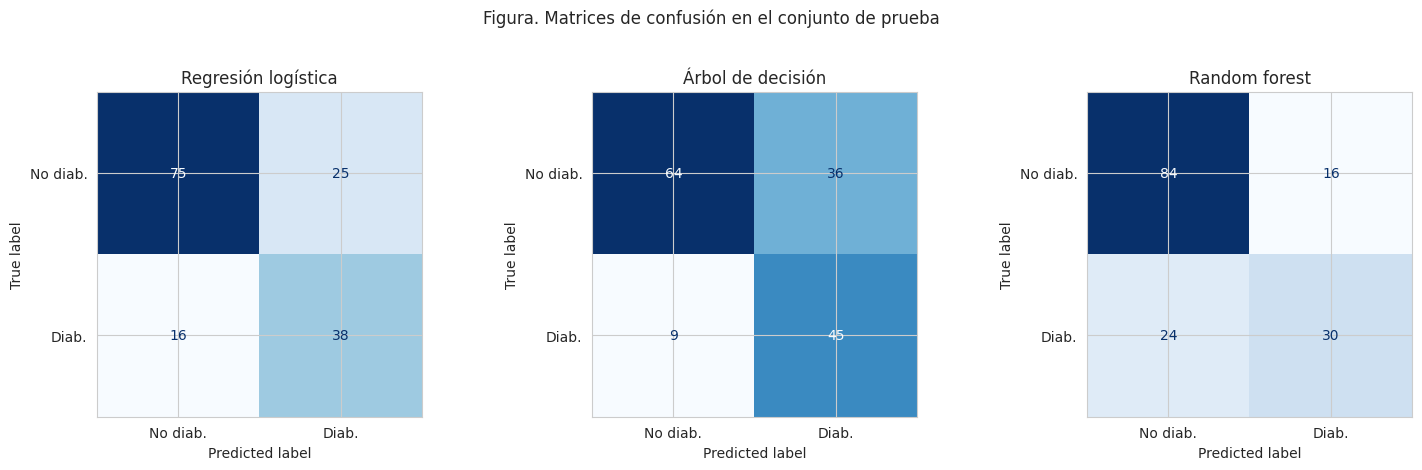

,VP,VN,FP (falsa alarma),FN (diabética no detectada)
Modelo,,,,
Regresión logística,38,75,25,16
Árbol de decisión,45,64,36,9
Random forest,30,84,16,24


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, nombre in zip(axes, modelos):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[nombre], display_labels=["No diab.", "Diab."],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nombre)
fig.suptitle("Figura. Matrices de confusión en el conjunto de prueba", y=1.03)
plt.tight_layout()
plt.show()

errores = []
for nombre in modelos:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[nombre]).ravel()
    errores.append({"Modelo": nombre, "VP": tp, "VN": tn, "FP (falsa alarma)": fp, "FN (diabética no detectada)": fn})
pd.DataFrame(errores).set_index("Modelo")

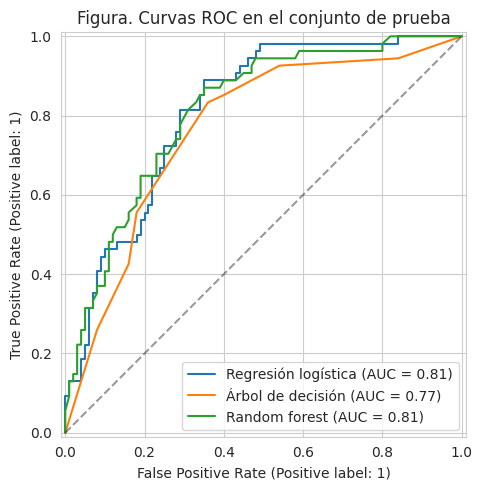

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for nombre in modelos:
    RocCurveDisplay.from_predictions(y_test, probas[nombre], name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=.4)
ax.set_title("Figura. Curvas ROC en el conjunto de prueba")
plt.tight_layout()
plt.show()

### 12.1 Validación cruzada (5 pliegues, solo sobre entrenamiento)

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas_cv = []
for nombre, m in modelos.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=["accuracy", "recall", "f1", "roc_auc"])
    filas_cv.append({"Modelo": nombre,
                     "Accuracy": f"{r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f}",
                     "Recall": f"{r['test_recall'].mean():.3f} ± {r['test_recall'].std():.3f}",
                     "F1": f"{r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}",
                     "AUC-ROC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}"})
tabla_cv = pd.DataFrame(filas_cv).set_index("Modelo")
tabla_cv

,Accuracy,Recall,F1,AUC-ROC
Modelo,,,,
Regresión logística,0.762 ± 0.011,0.701 ± 0.039,0.672 ± 0.013,0.844 ± 0.016
Árbol de decisión,0.707 ± 0.032,0.748 ± 0.118,0.637 ± 0.052,0.786 ± 0.027
Random forest,0.769 ± 0.028,0.589 ± 0.025,0.640 ± 0.036,0.822 ± 0.027


La validación cruzada muestra si el desempeño es estable entre distintas particiones; con solo 154 pacientes en prueba, una única división puede ser optimista o pesimista.

### 12.2 ¿Qué variables usa cada modelo?

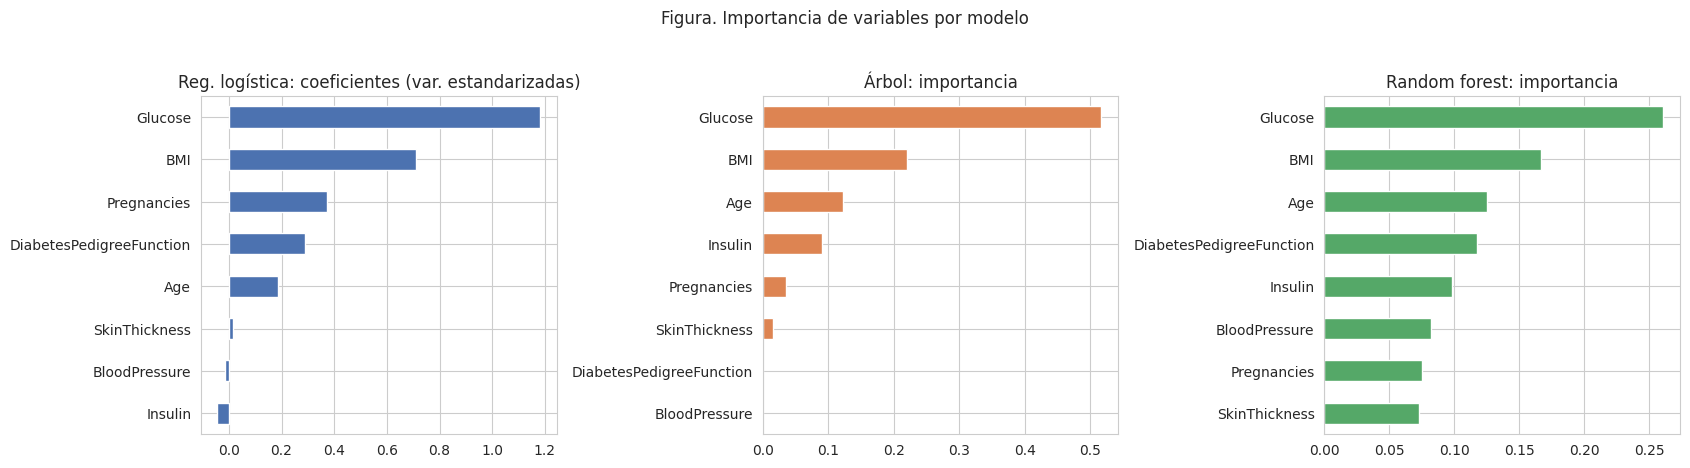

In [25]:
coef = pd.Series(modelos["Regresión logística"].named_steps["clf"].coef_[0], index=X.columns).sort_values()
imp_tree = pd.Series(modelos["Árbol de decisión"].named_steps["clf"].feature_importances_, index=X.columns).sort_values()
imp_rf = pd.Series(modelos["Random forest"].named_steps["clf"].feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
coef.plot(kind="barh", ax=axes[0], color="#4C72B0"); axes[0].set_title("Reg. logística: coeficientes (var. estandarizadas)")
imp_tree.plot(kind="barh", ax=axes[1], color="#DD8452"); axes[1].set_title("Árbol: importancia")
imp_rf.plot(kind="barh", ax=axes[2], color="#55A868"); axes[2].set_title("Random forest: importancia")
fig.suptitle("Figura. Importancia de variables por modelo", y=1.03)
plt.tight_layout()
plt.show()

*Los coeficientes e importancias describen asociaciones aprendidas por el modelo, no efectos causales.*

### 12.3 Análisis de errores

In [26]:
# Pacientes diabéticas no detectadas (falsos negativos) vs. detectadas, para el modelo con mayor recall
mejor_recall = tabla["Recall"].idxmax()
test = X_test.copy(); test["real"] = y_test; test["pred"] = preds[mejor_recall]
fn = test[(test.real == 1) & (test.pred == 0)]
vp = test[(test.real == 1) & (test.pred == 1)]
print(f"Modelo con mayor recall: {mejor_recall} → FN = {len(fn)}, VP = {len(vp)}")
print(pd.DataFrame({"FN (no detectadas)": fn[["Glucose", "BMI", "Age"]].mean(),
                    "VP (detectadas)": vp[["Glucose", "BMI", "Age"]].mean()}).round(1))

Modelo con mayor recall: Árbol de decisión → FN = 9, VP = 45
         FN (no detectadas)  VP (detectadas)
Glucose               119.4            144.1
BMI                    35.0             34.9
Age                    27.9             38.0


In [27]:
import json
resultados = {
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "pct_diab_train": round(float(y_train.mean() * 100), 1), "pct_diab_test": round(float(y_test.mean() * 100), 1),
    "metricas": tabla.reset_index().to_dict(orient="records"),
    "cv": tabla_cv.reset_index().to_dict(orient="records"),
    "errores": pd.DataFrame(errores).to_dict(orient="records"),
    "corr_obj": corr_obj.round(3).to_dict(),
    "importancia_rf": imp_rf.sort_values(ascending=False).round(3).to_dict(),
    "coef_lr": coef.sort_values(ascending=False).round(3).to_dict(),
}
with open("resultados_modelos.json", "w") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=1, default=int)
print("Resultados guardados en resultados_modelos.json (usados en el informe)")

Resultados guardados en resultados_modelos.json (usados en el informe)


## 12b. Guardado del pipeline para la aplicación (corte 3)

Se guarda el pipeline completo de la regresión logística (imputación por mediana + escalamiento + modelo) y el orden de las columnas. La app carga estos archivos y no reentrena. Los ceros imposibles se convierten a `NaN` antes de predecir, igual que en el entrenamiento.

In [ ]:
import joblib, sklearn

pipeline_final = modelos["Regresión logística"]
joblib.dump(pipeline_final, "modelo_diabetes.joblib")
joblib.dump(list(X_train.columns), "columnas.joblib")

# Comprobación: cargar y predecir un registro del conjunto de prueba
modelo = joblib.load("modelo_diabetes.joblib")
registro = X_test.iloc[[0]]
print("Índice del registro:", registro.index[0])
print("Clase predicha:", modelo.predict(registro)[0])
print("Probabilidad de diabetes:", round(modelo.predict_proba(registro)[0, 1], 4))
print("scikit-learn:", sklearn.__version__)

## 13. Conclusiones del notebook

**Principales hallazgos del EDA**
- El 34,9 % de las pacientes (268 de 768) es diabética: desbalance moderado, por lo que el accuracy por sí solo es insuficiente.
- `Glucose` es la variable más asociada al diagnóstico (r = 0,49), seguida de `BMI` (0,31), `Age` (0,24) y `Pregnancies` (0,22). La tasa de diabetes crece con el IMC y es menor en mujeres de 21-30 años.
- `Insulin` (48,7 %) y `SkinThickness` (29,6 %) tienen muchos ceros imposibles; la imputación con mediana crea un pico artificial en esas variables. No se eliminaron registros atípicos.

**¿Qué modelo produjo los resultados más adecuados y qué evidencias lo respaldan?**
Ninguno domina en todo; depende del error que más importe. Si en un tamizaje es más grave **no detectar** a una paciente diabética (falso negativo), el árbol de decisión tiene el mayor recall en prueba (0,833; solo 9 FN) pero el menor AUC (0,767), más falsas alarmas (36 FP) y un recall inestable en validación cruzada (0,748 ± 0,118). La **regresión logística** ofrece el mejor equilibrio y estabilidad: AUC similar al del random forest en prueba (0,813 frente a 0,812) y mayor en validación cruzada (0,844 frente a 0,822), mejor F1 en validación cruzada (0,672) y recall de 0,704 (16 FN). El **random forest** logra el accuracy más alto (0,740 en prueba; 0,769 en validación cruzada) pero el menor recall (0,556; 24 FN) y se sobreajusta (F1 de entrenamiento = 1,0). Por estas evidencias, la regresión logística se toma como modelo base preliminar (equilibrio entre recall, AUC y estabilidad), con el árbol como alternativa si se prioriza el recall.

**Errores y limitaciones**
- Evaluación sobre solo 154 pacientes en prueba; las diferencias entre modelos son pequeñas y pueden cambiar con otra partición.
- No se optimizaron hiperparámetros ni el umbral de decisión (0,5), que influye directamente en el balance FN/FP.
- Imputación por mediana como línea base; falta comparar alternativas (por grupo, KNN, indicador de dato faltante).
- Los 9 falsos negativos del árbol tienen glucosa media más baja (119,4 frente a 144,1) y son más jóvenes (27,9 frente a 38,0 años) que las diabéticas que sí detecta; esto sugiere que el árbol falla más cuando la glucosa no es marcadamente alta, aunque son pocos casos y no se analizó este patrón en los otros modelos.
- La glucosa a 2 h es parte del criterio diagnóstico, por lo que el problema se parece más a apoyo al diagnóstico que a predicción temprana; además el dataset solo incluye mujeres de origen Pima ≥ 21 años, lo que limita la generalización.
- Los resultados muestran asociaciones, no causalidad.
